In [4]:
import pandas as pd


In [5]:
import numpy as np


In [6]:
df=pd.read_csv("/content/Airline Dataset Updated - v2.csv")
df

,Passenger ID,First Name,Last Name,Gender,Age,Nationality,Airport Name,Airport Country Code,Country Name,Airport Continent,Continents,Departure Date,Arrival Airport,Pilot Name,Flight Status
0,ABVWIg,Edithe,Leggis,Female,62,Japan,Coldfoot Airport,US,United States,NAM,North America,6/28/2022,CXF,Fransisco Hazeldine,On Time
1,jkXXAX,Elwood,Catt,Male,62,Nicaragua,Kugluktuk Airport,CA,Canada,NAM,North America,12/26/2022,YCO,Marla Parsonage,On Time
2,CdUz2g,Darby,Felgate,Male,67,Russia,Grenoble-Isère Airport,FR,France,EU,Europe,1/18/2022,GNB,Rhonda Amber,On Time
3,BRS38V,Dominica,Pyle,Female,71,China,Ottawa / Gatineau Airport,CA,Canada,NAM,North America,9/16/2022,YND,Kacie Commucci,Delayed
4,9kvTLo,Bay,Pencost,Male,21,China,Gillespie Field,US,United States,NAM,North America,2/25/2022,SEE,Ebonee Tree,On Time
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98614,hnGQ62,Gareth,Mugford,Male,85,China,Hasvik Airport,NO,Norway,EU,Europe,12-11-2022,HAA,Pammie Kingscote,Cancelled
98615,2omEzh,Kasey,Benedict,Female,19,Russia,Ampampamena Airport,MG,Madagascar,AF,Africa,10/30/2022,IVA,Dorice Lochran,Cancelled
98616,VUPiVG,Darrin,Lucken,Male,65,Indonesia,Albacete-Los Llanos Airport,ES,Spain,EU,Europe,09-10-2022,ABC,Gearalt Main,On Time
98617,E47NtS,Gayle,Lievesley,Female,34,China,Gagnoa Airport,CI,Côte d'Ivoire,AF,Africa,10/26/2022,GGN,Judon Chasle,Cancelled


In [7]:
df.tail()

,Passenger ID,First Name,Last Name,Gender,Age,Nationality,Airport Name,Airport Country Code,Country Name,Airport Continent,Continents,Departure Date,Arrival Airport,Pilot Name,Flight Status
98614,hnGQ62,Gareth,Mugford,Male,85,China,Hasvik Airport,NO,Norway,EU,Europe,12-11-2022,HAA,Pammie Kingscote,Cancelled
98615,2omEzh,Kasey,Benedict,Female,19,Russia,Ampampamena Airport,MG,Madagascar,AF,Africa,10/30/2022,IVA,Dorice Lochran,Cancelled
98616,VUPiVG,Darrin,Lucken,Male,65,Indonesia,Albacete-Los Llanos Airport,ES,Spain,EU,Europe,09-10-2022,ABC,Gearalt Main,On Time
98617,E47NtS,Gayle,Lievesley,Female,34,China,Gagnoa Airport,CI,Côte d'Ivoire,AF,Africa,10/26/2022,GGN,Judon Chasle,Cancelled
98618,8JYEcz,Wilhelmine,Touret,Female,10,Poland,Yoshkar-Ola Airport,RU,Russian Federation,EU,Europe,4/16/2022,JOK,Auguste Tindley,Delayed


In [8]:
df.describe()

,Age
count,98619.000000
mean,45.504021
std,25.929849
min,1.000000
25%,23.000000
50%,46.000000
75%,68.000000
max,90.000000


In [9]:
df.dtypes

,0
Passenger ID,object
First Name,object
Last Name,object
Gender,object
Age,int64
Nationality,object
Airport Name,object
Airport Country Code,object
Country Name,object
Airport Continent,object


In [11]:
#seperate numeric and catergoric columns
numeric_columns = df.select_dtypes(include=['int64','float64']).columns.tolist()
categorical_columns = df.select_dtypes(include=['object']).columns.tolist()

In [12]:
#display results
print("\n Numeric Columns:")
print(numeric_columns)


 Numeric Columns:
['Age']


In [13]:
print("\n Categorical Columns:")
print(categorical_columns)


 Categorical Columns:
['Passenger ID', 'First Name', 'Last Name', 'Gender', 'Nationality', 'Airport Name', 'Airport Country Code', 'Country Name', 'Airport Continent', 'Continents', 'Departure Date', 'Arrival Airport', 'Pilot Name', 'Flight Status']


In [ ]:
#performimg data cleaning
#handling missing data
#removing null data

In [14]:
#show initial missing value count
print("missing values before cleaning:")
print(df.isnull().sum())

missing values before cleaning:
Passenger ID            0
First Name              0
Last Name               0
Gender                  0
Age                     0
Nationality             0
Airport Name            0
Airport Country Code    0
Country Name            0
Airport Continent       0
Continents              0
Departure Date          0
Arrival Airport         0
Pilot Name              0
Flight Status           0
dtype: int64


In [16]:
from sklearn.preprocessing import LabelEncoder

# create LabelEncoder object
encoder = LabelEncoder()

# Encode an existing categorical column, e.g., 'Flight Status'
df['Flight Status_encoded'] = encoder.fit_transform(df['Flight Status'])

# Display result
print(df[['Flight Status', 'Flight Status_encoded']].head())

  Flight Status  Flight Status_encoded
0       On Time                      2
1       On Time                      2
2       On Time                      2
3       Delayed                      1
4       On Time                      2


In [18]:
from sklearn.preprocessing import MinMaxScaler

# Select the existing numeric column from your dataset ('Age')
features = ['Age']

X = df[features]

# Rescale data
scaler = MinMaxScaler()
rescaled_data = scaler.fit_transform(X)

# Create a new dataframe with the rescaled data
df_rescaled = pd.DataFrame(rescaled_data, columns=X.columns)

# Display result
print(df_rescaled.head())

        Age
0  0.685393
1  0.685393
2  0.741573
3  0.786517
4  0.224719


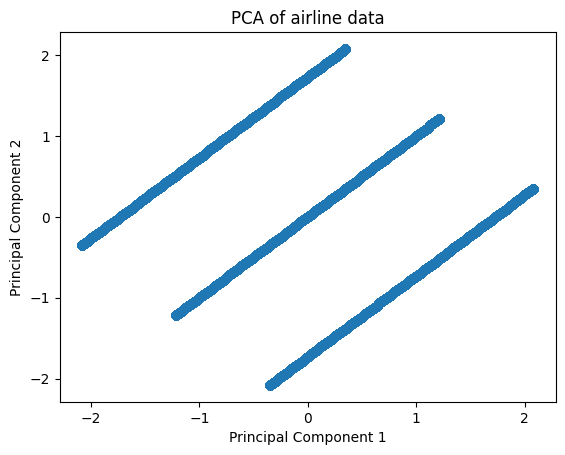

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

#Select numeric features (using 'Flight Status_encoded' which was created in cell Vzm1NRBU-1kD)
X=df[['Age','Flight Status_encoded']]

#Handle missing values
X=X.fillna(X.mean())

#Standardize the data
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

#Perform PCA
pca=PCA(n_components=2)
principle_components=pca.fit_transform(X_scaled)

#Plot
plt.scatter(principle_components[:,0],principle_components[:,1])
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of airline data")
plt.show()